# GSM8K dataset analysis

In [ ]:

from pathlib import Path
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

import json, torch, pandas as pd
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
from huggingface_hub import login

from eval_gsm8k.utils import extract_predicted_answer

os.chdir('..')

access_token = os.environ.get('HF_TOKEN', None)
if access_token is None:
    raise ValueError("Please set the HF_TOKEN environment variable with your Hugging Face token.")
login(token=access_token, add_to_git_credential=True)

/datassd/home/plazaro/.conda/envs/qwen-tunedlens-math/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# METADATA
results_paths = {
    "Qwen2.5_BASE": 'eval_results/GSM8K_Qwen__Qwen2.5-14B_2025-06-08_09-10-05',
    "Qwen2.5_GRPO": 'eval_results/GSM8K_outputs__Qwen2_5_14B_GRPO__checkpoint-1500_2025-06-08_09-14-30',
    "Qwen2.5_distil": 'eval_results/GSM8K_deepseek-ai__DeepSeek-R1-Distill-Qwen-14B_2025-06-08_23-36-11',
}

run_paths = {
    "base": results_paths["Qwen2.5_BASE"],
    "grpo": results_paths["Qwen2.5_GRPO"],
    "distil": results_paths["Qwen2.5_distil"],
}

# load all the tokenizers
tokenizers = {
    "base": AutoTokenizer.from_pretrained("Qwen/Qwen2.5-14B"),
    "grpo": AutoTokenizer.from_pretrained("outputs/Qwen2_5_14B_GRPO/checkpoint-1500"),
    "distil": AutoTokenizer.from_pretrained("deepseek-ai/DeepSeek-R1-Distill-Qwen-14B"),
}

In [3]:
# MISCELANEOUS FUNCTIONS
def recover_index(run_dir):
    """
    Recover the index from the results directory.
    """
    index_path = Path(run_dir) / "index.json"
    if not index_path.exists():
        raise FileNotFoundError(f"Index file not found: {index_path}")
    
    with open(index_path, 'r', encoding='utf-8') as f:
        index_data = json.load(f)
    
    return pd.DataFrame(index_data)

def print_accuracy(df):
    """
    Print the accuracy of the model based on the DataFrame.
    """
    total = len(df)
    correct = df['correct'].sum()
    accuracy = correct / total * 100
    print(f"Accuracy: {accuracy:.2f}% ({correct}/{total})")

def get_idxs(row, tokenizer):
    """
    Get the indices of the tokens that correspond to the predicted answer in the text answer.
    """
    # Get data from row
    text_answer = row['model_answers_text'][0]
    predicted_answer = row['extracted_model_answers'][0]

    # Search for the last predicted answer in the text answer
    start_char = text_answer.rfind(predicted_answer)
    if start_char == -1:
        return []

    # Get where it ends
    end_char = start_char + len(predicted_answer)
    enc = tokenizer(text_answer, add_special_tokens=False, return_offsets_mapping=True)
    offsets = enc["offset_mapping"]
    
    # Get all the idxs
    idxs = [
        i for i, (start, end) in enumerate(offsets)
        if not (end <= start_char or start >= end_char)
    ]
    
    return idxs

In [4]:
# RESULTS FUNCTIONS

def extract_entropy_data(row, run_dir, tokenizer):
    """
    layerwise_entropy: [num_layers]
    overall_entropy: scalar
    """
    idxs = get_idxs(row, tokenizer)
    arr = torch.load(os.path.join(run_dir, row["entropy_file"]), weights_only=False)
    # If no final answer, return nan array
    if not idxs:
        num_layers = arr.shape[0]
        return torch.full((num_layers,), float('nan')), float('nan')
    # Now I get the entropy values for the idxs
    result_entropy = arr[:,idxs]
    # avg over tokens
    result_layerwise_entropy = result_entropy.mean(axis=1)
    # avg everything
    result_auc = result_layerwise_entropy.sum().item()
    # Get input length
    input_tokens = tokenizer.encode(row['question'], add_special_tokens=False)
    input_len = len(input_tokens)
    # Get reasoning tokens mean entropy
    reasoning_layerwise_entropy = arr[:, input_len:idxs[0]].mean(axis=1)
    reasoning_auc = reasoning_layerwise_entropy.sum().item()  # AUC is sum of the layerwise entropies
    # Now for the last layer
    last_result_entropy = arr[-1, idxs].mean().item()
    last_reasoning_entropy = arr[-1, input_len:idxs[0]].mean().item()
    return result_layerwise_entropy, result_auc, reasoning_layerwise_entropy, reasoning_auc, last_result_entropy, last_reasoning_entropy

def extract_target_avg_logp(row, run_dir):
    """
    Extract the average log probability of the target answer from the row data.
    output shape: [num_layers]
    overall_logp: scalar
    """
    arr = torch.load(os.path.join(run_dir, row["layer_avg_logp_file"]), weights_only=False)
    result_auc = arr.sum().item()  # AUC is sum of the layerwise log probabilities
    # Now the last layer
    last_result = arr[-1].item()
    return arr, result_auc, last_result

def extract_forward_kl_data(row, run_dir, tokenizer):
    """
    layerwise_forward_kl: [num_layers]
    overall_forward_kl: scalar
    """
    idxs = get_idxs(row, tokenizer)
    arr = torch.load(os.path.join(run_dir, row["forward_kl_file"]), weights_only=False)
    # If no final answer, return nan array
    if not idxs:
        num_layers = arr.shape[0]
        return torch.full((num_layers,), float('nan')), float('nan')
    # Now I get the forward KL values for the idxs
    result_forward_kl = arr[:, idxs]
    # avg over tokens
    result_layerwise_fkl = result_forward_kl.mean(axis=1)
    # avg everything
    result_auc = result_layerwise_fkl.sum()
    # Get input length
    input_tokens = tokenizer.encode(row['question'], add_special_tokens=False)
    input_len = len(input_tokens)
    # get reasoning tokens mean forward KL
    reasoning_layerwise_fkl = arr[:, input_len:idxs[0]].mean(axis=1)
    reasoning_auc = reasoning_layerwise_fkl.sum().item()
    # Now for the last layer
    last_result_fkl = arr[-1, idxs].mean().item()
    last_reasoning_fkl = arr[-1, input_len:idxs[0]].mean().item()
    return result_layerwise_fkl, result_auc, reasoning_layerwise_fkl, reasoning_auc, last_result_fkl, last_reasoning_fkl

def load_topk(row, run_dir, what="final"):
    """Return a dict with keys logp / ids / toks for 'final' or 'layer'."""
    prefix = "topk_final_" if what == "final" else "topk_layer_"
    logp   = torch.load(os.path.join(run_dir, row[f"{prefix}log_probs_file"]),
                        weights_only=False)
    ids    = torch.load(os.path.join(run_dir, row[f"{prefix}ids_file"]),
                        weights_only=False)
    toks   = torch.load(os.path.join(run_dir, row[f"{prefix}tokens_file"]),
                        weights_only=False)
    return dict(logp=logp, ids=ids, toks=toks)

def summarise_final_topk(topk_dict, answer_token_ids):
    """
    * margin:   mean(logp_rank1 - logp_rank2)          → confidence
    Es cuánto de margen hay entre el primero y el último
    """
    logp = topk_dict["logp"]           # (T, K)
    ids  = topk_dict["ids"]            # (T, K)
    T, K = logp.shape          # ← extract T (positions) and K (top-K)

    rank1 = logp[:, 0]
    rank2 = logp[:, 1]
    margin = (rank1 - rank2).mean().item()

    return dict(final_margin      = margin)

In [5]:
# Stats functions
def descriptive_stats(df, metric):
    grp = df.groupby('run')[metric]
    stats = grp.agg(
        mean   = 'mean',
        median = 'median',
        Q1    = lambda x: x.quantile(0.25),
        Q3    = lambda x: x.quantile(0.75),
        min    = 'min',
        max    = 'max',
    )
    return stats

def cliffs_delta(x, y):
    """Compute Cliff’s delta effect size between two 1D arrays."""
    x = np.asarray(x)
    y = np.asarray(y)
    n1, n2 = len(x), len(y)
    # count how many times xi > yj and xi < yj
    greater = sum(np.sum(xi > y)   for xi in x)
    lesser  = sum(np.sum(xi < y)   for xi in x)
    return (greater - lesser) / (n1 * n2)

def pairwise_stats(df, metric, pairs):
    results = []
    for a, b in pairs:
        #xa = df.loc[df['run']==a, metric]
        #xb = df.loc[df['run']==b, metric]
        # Adapt for nans
        group_a = df[(df['run'] == a) & df[metric].notna()][['id', metric]]
        group_b = df[(df['run'] == b) & df[metric].notna()][['id', metric]]
        # Align by shared IDs
        merged = pd.merge(group_a, group_b, on='id', suffixes=('_a', '_b'))
        # Now as usual
        xa = merged[f'{metric}_a'].values
        xb = merged[f'{metric}_b'].values
        stat, p = wilcoxon(xa, xb)
        med_diff = np.median(xa - xb)
        d = cliffs_delta(xa, xb)
        results.append({
            'Model_A': a,
            'Model_B': b,
            'p-value': p,
            'median_diff': med_diff,
            "cliff's delta": d
        })
    return pd.DataFrame(results)

In [6]:
# Load index data and convert to DataFrames
base_df = recover_index(results_paths["Qwen2.5_BASE"])
grpo_df = recover_index(results_paths["Qwen2.5_GRPO"])
distil_df = recover_index(results_paths["Qwen2.5_distil"])

# Build the big dataframe
for name, df in [
    ("base", base_df),
    ("grpo", grpo_df),
    ("distil", distil_df),
]:
    df["run"] = name
all_df = pd.concat([base_df, grpo_df, distil_df], ignore_index=True)

# Get accuracies
all_df.groupby("run")["correct"].mean()

run
base      0.826384
distil    0.705838
grpo      0.878696
Name: correct, dtype: float64

In [7]:
# Also get accuracies this way
print("Accuracy for Qwen2.5_BASE:")
print_accuracy(base_df)
print("\nAccuracy for Qwen2.5_GRPO:")
print_accuracy(grpo_df)
print("\nAccuracy for Qwen2.5_distil:") #! Este coger los fallos y comprobarlos a mano, tampoco son tantos
print_accuracy(distil_df)

Accuracy for Qwen2.5_BASE:
Accuracy: 82.64% (1090/1319)

Accuracy for Qwen2.5_GRPO:
Accuracy: 87.87% (1159/1319)

Accuracy for Qwen2.5_distil:
Accuracy: 70.58% (931/1319)


In [8]:
export = distil_df.loc[distil_df['correct'] == 0].copy()
export = export[['id', 'question', 'model_answers_text', 'ground_answer_text']]
export.to_json('distil_errors.json', orient='records', indent=2)

In [9]:
export = grpo_df.loc[grpo_df['correct'] == 0].copy()
export = export[['id', 'question', 'model_answers_text', 'ground_answer_text']]
export.to_json('grpo_errors.json', orient='records', indent=2)

In [10]:
export = base_df.loc[base_df['correct'] == 0].copy()
export = export[['id', 'question', 'model_answers_text', 'ground_answer_text']]
export.to_json('base_errors.json', orient='records', indent=2)

In [ ]:
# Analyze the correct results
correct_df = all_df[all_df["correct"] == 1].copy()

# Get entropies results
correct_df[["res_layer_entropy", "res_auc_entropy",
            "rea_layer_entropy", "rea_auc_entropy",
            "res_last_entropy", "rea_last_entropy"]] = correct_df.apply(
    lambda r: pd.Series(extract_entropy_data(r, run_paths[r["run"]], tokenizers[r["run"]])),
    axis=1
)

# Get the logp results
correct_df[["res_layer_logp", "res_auc_logp", "res_last_logp"]] = correct_df.apply(
    lambda r: pd.Series(extract_target_avg_logp(r, run_paths[r["run"]])),
    axis=1
)

# Get the forward KL results
correct_df[["res_layer_fkl", "res_auc_fkl",
            "rea_layer_fkl", "rea_auc_fkl",
            "res_last_fkl", "rea_last_fkl"]] = correct_df.apply(
    lambda r: pd.Series(extract_forward_kl_data(r, run_paths[r["run"]], tokenizers[r["run"]])),
    axis=1
)

# Get the top-k final layer summarized results
correct_df = correct_df.join(
    correct_df.apply(lambda r:
        pd.Series(summarise_final_topk(
            load_topk(r, run_paths[r["run"]], "final"),
            r["output_tokens"]                      # or r["answer_token_ids"]
        )), axis=1))


In [12]:
correct_df.columns

Index(['id', 'question', 'ground_answer_text', 'model_answers_text',
       'extracted_model_answers', 'extracted_ground_answer', 'majority_answer',
       'correct', 'output_tokens', 'entropy_file', 'forward_kl_file',
       'layer_avg_logp_file', 'topk_final_log_probs_file',
       'topk_final_ids_file', 'topk_final_tokens_file',
       'topk_layer_log_probs_file', 'topk_layer_ids_file',
       'topk_layer_tokens_file', 'run', 'res_layer_entropy', 'res_auc_entropy',
       'rea_layer_entropy', 'rea_auc_entropy', 'res_last_entropy',
       'rea_last_entropy', 'res_layer_logp', 'res_auc_logp', 'res_last_logp',
       'res_layer_fkl', 'res_auc_fkl', 'rea_layer_fkl', 'rea_auc_fkl',
       'res_last_fkl', 'rea_last_fkl', 'final_margin'],
      dtype='object')

In [13]:
print("=== res_auc_entropy ===")
print(descriptive_stats(correct_df, 'res_auc_entropy'), "\n")
print("=== rea_auc_entropy ===")
print(descriptive_stats(correct_df, 'rea_auc_entropy'), "\n")
print("=== res_last_entropy ===")
print(descriptive_stats(correct_df, 'res_last_entropy'), "\n")
#print("=== rea_last_entropy ===")
#print(descriptive_stats(correct_df, 'rea_last_entropy'), "\n")

print("=== res_auc_fkl ===")
print(descriptive_stats(correct_df, 'res_auc_fkl'), "\n")
print("=== rea_auc_fkl ===")
print(descriptive_stats(correct_df, 'rea_auc_fkl'), "\n")

print("=== res_auc_logp ===")
print(descriptive_stats(correct_df, 'res_auc_logp'), "\n")
print("=== res_last_logp ===")
print(descriptive_stats(correct_df, 'res_last_logp'), "\n")
print("=== final_margin ===")
print(descriptive_stats(correct_df, 'final_margin'), "\n")

=== res_auc_entropy ===
              mean   median         Q1         Q3       min     max
run                                                                
base    153.105716  147.125  138.12500  158.37500  107.4375  352.00
distil  149.628997  140.500  125.90625  161.00000   83.1875  339.75
grpo    178.494647  174.125  160.75000  190.53125  118.0000  343.75 

=== rea_auc_entropy ===
              mean   median        Q1       Q3       min      max
run                                                              
base    145.189345  145.125  134.0000  155.375   64.1875  217.875
distil  149.047843  148.250  143.3750  154.625  118.9375  175.625
grpo    189.361080  195.125  183.3125  203.500   81.3125  277.750 

=== res_last_entropy ===
            mean    median        Q1        Q3  min       max
run                                                          
base    0.285489  0.266846  0.182739  0.321289  0.0  1.373047
distil  0.063739  0.001589  0.000073  0.034073  0.0  1.475586
grpo 

In [14]:
pairs = [('base','grpo'), ('base','distil'), ('grpo','distil')]

print("Pairwise for res_auc_entropy:")
print(pairwise_stats(correct_df, 'res_auc_entropy', pairs), "\n")
print("Pairwise for rea_auc_entropy:")
print(pairwise_stats(correct_df, 'rea_auc_entropy', pairs), "\n")
print("Pairwise for res_last_entropy:")
print(pairwise_stats(correct_df, 'res_last_entropy', pairs), "\n")
#print("Pairwise for rea_last_entropy:")
#print(pairwise_stats(correct_df, 'rea_last_entropy', pairs), "\n")

print("Pairwise for res_auc_fkl:")
print(pairwise_stats(correct_df, 'res_auc_fkl', pairs), "\n")
print("Pairwise for rea_auc_fkl:")
print(pairwise_stats(correct_df, 'rea_auc_fkl', pairs), "\n")

print("Pairwise for res_auc_logp:")
print(pairwise_stats(correct_df, 'res_auc_logp', pairs), "\n")
print("Pairwise for res_last_logp:")
print(pairwise_stats(correct_df, 'res_last_logp', pairs), "\n")
print("Pairwise for final_margin:")
print(pairwise_stats(correct_df, 'final_margin', pairs), "\n")

Pairwise for res_auc_entropy:
  Model_A Model_B        p-value  median_diff  cliff's delta
0    base    grpo  6.419277e-106      -24.875      -0.606359
1    base  distil   2.267079e-12        8.625       0.217307
2    grpo  distil   4.102851e-93       33.375       0.599368 

Pairwise for rea_auc_entropy:
  Model_A Model_B        p-value  median_diff  cliff's delta
0    base    grpo  5.004433e-109     -47.1250      -0.784172
1    base  distil   9.753183e-03      -2.0000      -0.100885
2    grpo  distil  3.310871e-119      45.9375       0.817932 

Pairwise for res_last_entropy:
  Model_A Model_B        p-value  median_diff  cliff's delta
0    base    grpo  3.515417e-152     0.242950       0.870624
1    base  distil  8.285572e-100     0.241882       0.770029
2    grpo  distil   4.660954e-10    -0.000248      -0.180625 

Pairwise for res_auc_fkl:
  Model_A Model_B       p-value  median_diff  cliff's delta
0    base    grpo  2.556359e-78   -30.609177      -0.508572
1    base  distil  2.8744

**final_margin**
Es la diferencia de probabilidad entre el rank 1 y el rank2. Cuanto mayor sea, más seguro está el modelo en el token final.


# Now the plots

In [15]:
def cool_boxplot(data, models, y_label, title):
    # ——————————————————————————
    # Wada-inspired palette (beniiro, aotake, kigiki)
    # ——————————————————————————
    colors = ['#1b9e77',  
            '#d95f02',  
            '#7570b3']  

    # ——————————————————————————
    # Plot
    # ——————————————————————————
    fig, ax = plt.subplots(figsize=(6, 4))

    box = ax.boxplot(
        data,
        labels=models,
        notch=False,
        patch_artist=True,
        showfliers=True,
        widths=0.6,
        flierprops=dict(marker='o', markersize=4, markerfacecolor='gray', alpha=0.5, markeredgewidth=0),
        medianprops=dict(color='k', linewidth=1.5),
        whiskerprops=dict(color='k', linewidth=1.2),
        capprops=dict(color='k', linewidth=1.2),
        boxprops=dict(linewidth=1.2)
    )

    # fill each box with its Wada color
    for patch, color in zip(box['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.8)

    # axis labels & grid
    ax.set_xlabel('Model', fontsize=12)
    ax.set_ylabel(y_label, fontsize=12)
    ax.set_title(title, fontsize=14, pad=10)
    ax.yaxis.grid(True, linestyle='--', linewidth=0.6, alpha=0.7)
    ax.set_axisbelow(True)

    # tighten
    plt.tight_layout()
    plt.show()

/tmp/ipykernel_2362972/2605161209.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = ax.boxplot(


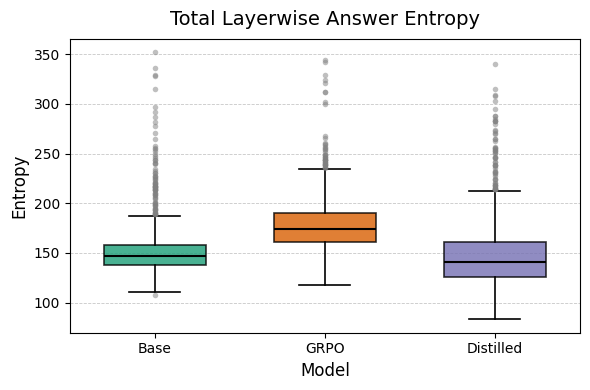

In [16]:
# boxplot
runs = ['base', 'grpo', 'distil']  # order you want on the x-axis
data = [correct_df.loc[correct_df['run']==r, 'res_auc_entropy'].dropna().values for r in runs]

cool_boxplot(data, 
             models = ["Base", "GRPO", "Distilled"],
             y_label='Entropy',
             title='Total Layerwise Answer Entropy')

/tmp/ipykernel_2362972/2605161209.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = ax.boxplot(


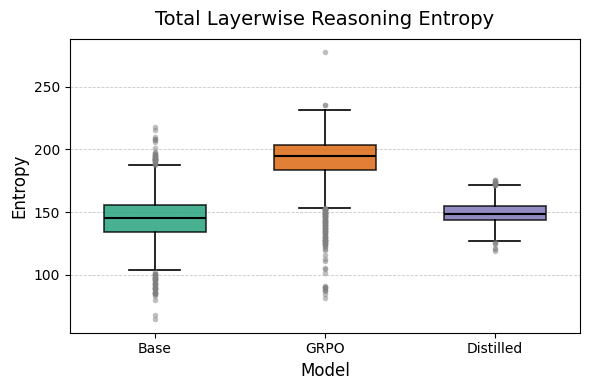

In [17]:
# boxplot
runs = ['base', 'grpo', 'distil']  # order you want on the x-axis
data = [correct_df.loc[correct_df['run']==r, 'rea_auc_entropy'].dropna().values for r in runs]

cool_boxplot(data, 
             models = ["Base", "GRPO", "Distilled"],
             y_label='Entropy',
             title='Total Layerwise Reasoning Entropy')

/tmp/ipykernel_2362972/2605161209.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = ax.boxplot(


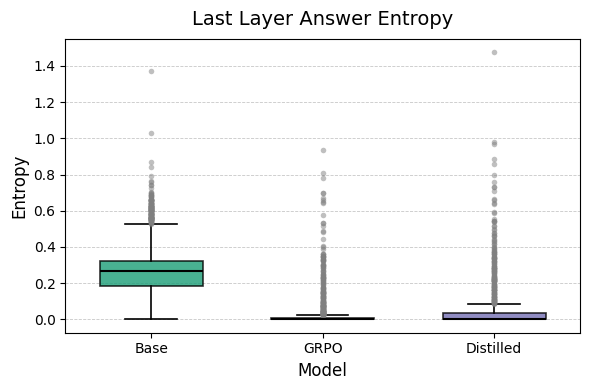

In [18]:
# boxplot
runs = ['base', 'grpo', 'distil']  # order you want on the x-axis
data = [correct_df.loc[correct_df['run']==r, 'res_last_entropy'].dropna().values for r in runs]

cool_boxplot(data, 
             models = ["Base", "GRPO", "Distilled"],
             y_label= 'Entropy',
             title='Last Layer Answer Entropy')

/tmp/ipykernel_2362972/2605161209.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = ax.boxplot(


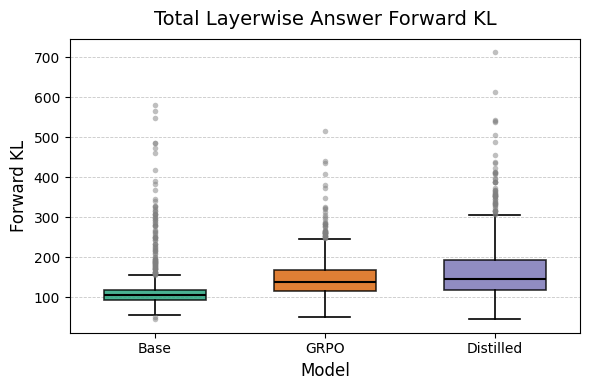

In [19]:
# boxplot
runs = ['base', 'grpo', 'distil']  # order you want on the x-axis
data = [correct_df.loc[correct_df['run']==r, 'res_auc_fkl'].dropna().values for r in runs]

cool_boxplot(data, 
             models = ["Base", "GRPO", "Distilled"],
             y_label='Forward KL',
             title='Total Layerwise Answer Forward KL')

/tmp/ipykernel_2362972/2605161209.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = ax.boxplot(


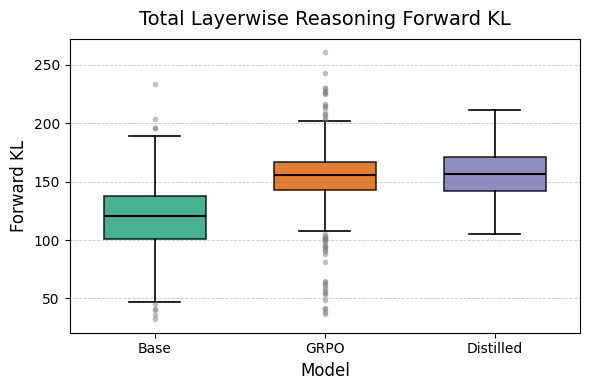

In [20]:
# boxplot
runs = ['base', 'grpo', 'distil']  # order you want on the x-axis
data = [correct_df.loc[correct_df['run']==r, 'rea_auc_fkl'].dropna().values for r in runs]

cool_boxplot(data, 
             models = ["Base", "GRPO", "Distilled"],
             y_label='Forward KL',
             title='Total Layerwise Reasoning Forward KL')

/tmp/ipykernel_2362972/2605161209.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = ax.boxplot(


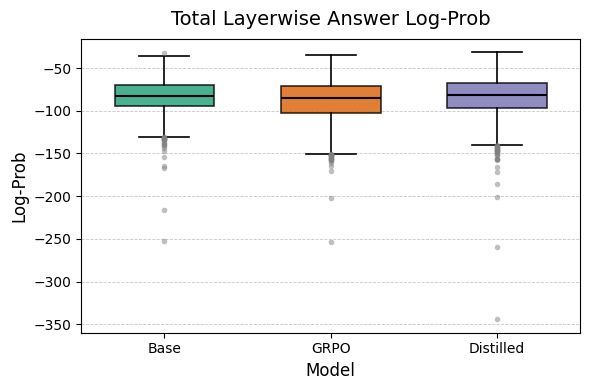

In [21]:
# boxplot
runs = ['base', 'grpo', 'distil']  # order you want on the x-axis
data = [correct_df.loc[correct_df['run']==r, 'res_auc_logp'].dropna().values for r in runs]

cool_boxplot(data, 
             models = ["Base", "GRPO", "Distilled"],
             y_label='Log-Prob',
             title='Total Layerwise Answer Log-Prob')

/tmp/ipykernel_2928747/2605161209.py:14: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = ax.boxplot(


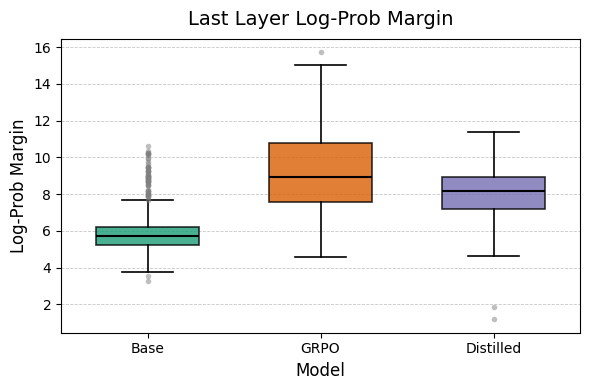

In [21]:
# boxplot
runs = ['base', 'grpo', 'distil']  # order you want on the x-axis
data = [correct_df.loc[correct_df['run']==r, 'final_margin'].values for r in runs]

cool_boxplot(data, 
             models = ["Base", "GRPO", "Distilled"],
             y_label='Log-Prob Margin',
             title='Last Layer Log-Prob Margin')


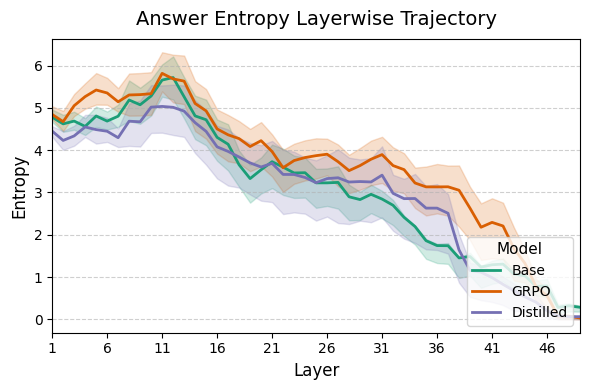

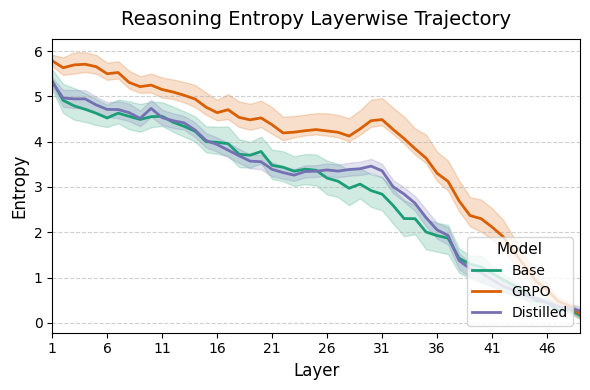

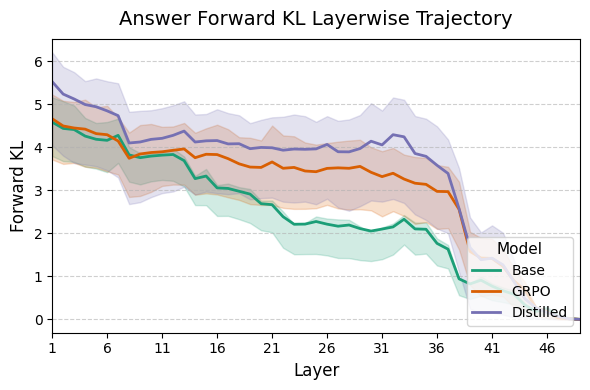

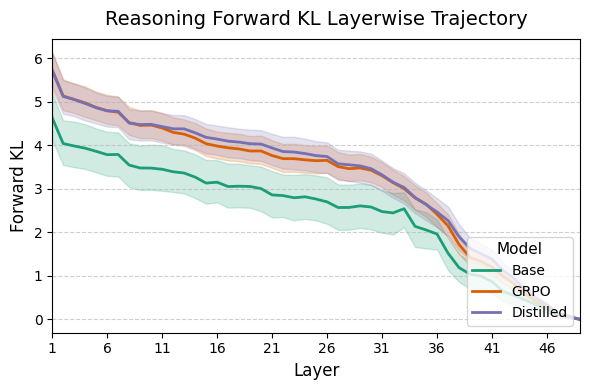

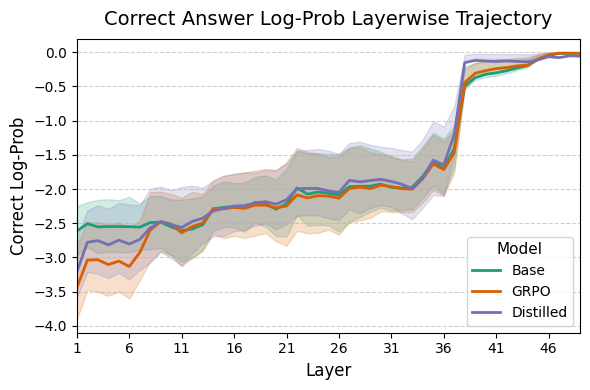

In [37]:
# Example DataFrame column names:
# - "run": model name (base, grpo, distil)
# - "layerwise_entropy", "layerwise_forward_kl", "target_avg_logp": lists/arrays per example

# Determine layer count and layer indices
n_layers = len(correct_df["res_layer_entropy"].iloc[0])
layers = np.arange(1, n_layers + 1)  # human‐friendly 1-based indexing

# Color palette (Sanzo Wada inspired)
colors = {
    "base":  "#1b9e77",   # Teal
    "grpo":  "#d95f02",   # Orange
    "distil":"#7570b3"    # Purple
}

# Metrics to plot
metrics = [
    ("res_layer_entropy",    "Entropy",           "Answer Entropy Layerwise Trajectory"),
    ("rea_layer_entropy",    "Entropy",           "Reasoning Entropy Layerwise Trajectory"),
    ("res_layer_fkl",       "Forward KL",        "Answer Forward KL Layerwise Trajectory"),
    ("rea_layer_fkl",       "Forward KL",        "Reasoning Forward KL Layerwise Trajectory"),
    ("res_layer_logp",      "Correct Log‐Prob",   "Correct Answer Log-Prob Layerwise Trajectory"),
]

for col, ylabel, title in metrics:
    fig, ax = plt.subplots(figsize=(6, 4))
    for run, label in zip(["base", "grpo", "distil"], ["Base", "GRPO", "Distilled"]):
        # stack per-example trajectories
        #arrs = np.stack(correct_df[correct_df["run"] == run][col].values)
        seqs = correct_df.loc[correct_df["run"] == run, col].dropna().tolist()
        # 2) convert to numpy and keep only the ones with correct length
        valid = []
        for s in seqs:
            arr = np.asarray(s, dtype=float)
            if arr.shape[0] == n_layers:
                valid.append(arr)
        if len(valid) == 0:
            continue
        arrs = np.stack(valid, axis=0)
        
        # compute summary curve and quartile bands
        mean_curve = np.nanmean(arrs, axis=0)
        lower_q25 = np.nanpercentile(arrs, 25, axis=0)
        upper_q75 = np.nanpercentile(arrs, 75, axis=0)
        
        # plot mean trajectory
        ax.plot(layers, mean_curve, label=label,
                color=colors[run], linewidth=2)
        # shade IQR band
        ax.fill_between(layers, lower_q25, upper_q75,
                        color=colors[run], alpha=0.2)

    # Styling
    ax.set_title(title, fontsize=14, pad=10)
    ax.set_xlabel("Layer", fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.set_xticks(layers[::5])
    ax.set_xticklabels(layers[::5])
    ax.set_xlim(1, n_layers)
    ax.grid(axis='y', linestyle='--', alpha=0.6)
    ax.legend(title="Model", fontsize=10, title_fontsize=11, loc='lower right')
    plt.tight_layout()
    plt.show()


# OLD stats

In [ ]:
def summarise_layer_topk(topk_dict, row, tokenizer):
    """
    | feature                  | code sketch                                          | intuition                                               |
    | ------------------------ | ---------------------------------------------------- | ------------------------------------------------------- |
    | **Layer-of-first-match** | `first = (ids == true_id).any(-1).float().argmax(0)` | “How deep before the correct token appears in top-K?”   |
    | **Rank trajectory**      | `ranks = (ids == true_id).float().argmax(-1)+1`      | Monotonic decrease ↘︎ ⇒ steady evidence building        |
    | **Log-prob trajectory**  | `lp_true = torch.gather(logp, -1, rank_idx)`         | Shows sharpening of belief; integrate (AUC) over layers |
    | **KL to final layer**    | `kl = F.kl_div(final_logp, logp, log_target=True)`   | Depth-wise convergence to the last layer distribution   |

    """
    logp = topk_dict["logp"]      # (L,T,K)
    ids  = topk_dict["ids"]       # (L,T,K) Los ids son los tokens en numericos. Los tokes son las strings
    L, T, K = logp.shape
    # Get the numeric final answer idxs
    idxs = get_idxs(row, tokenizer)
    # Get output tokens
    answer_token_ids = row['output_tokens']

    ranks = torch.full((L,T), K+1, dtype=torch.long)
    for l in range(L):
        for t, true_id in zip(idxs, row['extracted_ground_answer']):
            hits = (ids[l,t] == answer_token_ids[t]).nonzero()
            if hits.numel():
                ranks[l,t] = hits.item()+1

    # get the first layer where the correct token appears in top-K
    first_layer = (ranks < K+1).float().argmax(0).float().mean().item()
    avg_rank_curve = ranks.float().mean(1)          # length-L vector
    auc_rank = torch.trapz((K+1) - avg_rank_curve, dx=1).item()/(L*(K))

    return dict(layer_first_match = first_layer,
                auc_rank_inv      = auc_rank)


# Get the top-k layer-wise summarized results
correct_df = correct_df.join(
    correct_df.apply(lambda r:
        pd.Series(summarise_layer_topk(
            load_topk(r, run_paths[r["run"]], "layer"),
            r,
            tokenizers[r["run"]]
        )), axis=1))


**final_hit_rank_mu**
Creo que la métrica del final_hit no me vale, porque al completar por K+1 si aparece desde antes se me ha ido la media hacia ahí, porque debe ser que puede aparecer antes o algo así (?). No, esque estoy completando con K+1 si no está, cuando igual debería completar con Nan, o pasar de esta métrica, no sé si es útil.
**layer_first_match**
Media de la capa en la que aparece el true token entre los top k.
**auc_rank_inv**
El área bajo la curva del rango. Pero K es tan pequeño que creo que no sirve de nada la verdad.

In [ ]:
def summarise_final_topk(topk_dict, answer_token_ids):
    """
    * margin:   mean(logp_rank1 - logp_rank2)          → confidence
    Es cuánto de margen hay entre el primero y el último
    * hit_rank: list of ranks (1..K) for *true* token  → correctness ease
    Es dónde está el token correcto en el top-K
    * mass_topk: mean(logsumexp(logp_topk))
    Es cuánto de probabilidad se concentra en el top-K, aunque estando
    la entropía, es un poco redundante
    """
    logp = topk_dict["logp"]           # (T, K)
    ids  = topk_dict["ids"]            # (T, K)
    T, K = logp.shape          # ← extract T (positions) and K (top-K)

    rank1 = logp[:, 0]
    rank2 = logp[:, 1]
    margin = (rank1 - rank2).mean().item()

    # where does the emitted token sit inside its own top-K row?
    hit_rank = []
    for row_ids, true_id in zip(ids, answer_token_ids):
        # if token was forced in, it could be anywhere 0..K-1
        rank = (row_ids == true_id).nonzero(as_tuple=False)
        hit_rank.append( (rank.item()+1) if rank.numel() else K+1 )
    hit_rank = torch.tensor(hit_rank)

    mass = torch.logsumexp(logp, dim=-1).mean().item()

    return dict(final_margin      = margin,
                final_hit_rank_mu = hit_rank.float().mean().item(),
                final_mass_topk   = mass)